# Mouse transcriptome v2

This notebook builds the mouse v2 reference and compares it to v1.

v2 picks one transcript per gene from APPRIS: the longest principal, protein-coding, with a
proper start and stop codon. It then drops read-through genes and transcripts that sit inside
a longer one, and keeps all 13 mitochondrial genes. v1 did not do these steps.

In [1]:
! ls ..

raw                    riboflow_annot_and_ref scripts


In [2]:
# PYTHON MODULES
import sys
import os
import gzip
import hashlib
import warnings
from collections import defaultdict

import matplotlib
import matplotlib.pyplot as plt
from matplotlib_venn import venn2_unweighted
warnings.filterwarnings("ignore", message="venn2_unweighted is deprecated")

import pandas as pd
import numpy as np

from IPython.display import Markdown, display_html, display

sys.path.insert(0, '../../../..')
import ref_lib
from ref_lib.Fasta import FastaFile, FastaEntry

# Reuse the read-through gene reader from the reference builder in this folder
import generate_appris_reference as gen

%matplotlib inline

Reference, annotation and generated-output files we'll be using:

In [3]:
# Raw inputs used to build v2
transcripts_fasta = "../raw/sequence/gencode.vM39.pc_transcripts.fa.gz"
gencode_gtf       = "../raw/annotation/gencode.vM39.primary_assembly.annotation.gtf.gz"
appris_file       = "../raw/annotation/appris_data.principal.txt"

# Generated v2 outputs (produced by generate_riboflow_ref_and_annot.sh)
v2_selected_fasta = "../riboflow_annot_and_ref/appris_mouse_v2_selected.fa.gz"
v2_regions_bed    = "../riboflow_annot_and_ref/appris_mouse_v2_actual_regions.bed"

# Previous (v1) reference for comparison
v1_selected_fasta = "../../v1/riboflow_annot_and_ref/appris_mouse_v1_selected.fa.gz"

## Loading the generated v2 reference

Rather than re-running the whole selection, we read the files the pipeline already
produced: the selected FASTA (sequences) and the `_actual_regions.bed` (UTR5/CDS/UTR3
coordinates, 0-based and relative to the transcript, with the stop codon excluded from
the CDS as in the GTF).

In [4]:
def load_selected(fasta_path, regions_bed_path):
    # Relative region coordinates (BED: 0-based, end-excluded), keyed by transcript id
    regions = defaultdict(dict)
    with open(regions_bed_path) as bed:
        for line in bed:
            ref, start, end, name, score, strand = line.rstrip("\n").split("\t")
            tx = ref.split("|")[0].split(".")[0]
            regions[tx][name] = (int(start), int(end))

    selected = defaultdict(dict)
    for entry in FastaFile(fasta_path):
        fields = entry.header.split("|")
        tx   = fields[0].split(".")[0]
        gene = fields[1].split(".")[0]
        name = fields[5] if len(fields) > 5 else fields[0]
        r = regions.get(tx, {})
        selected[gene][tx] = {
            "name": name,
            "seq": entry.sequence,
            "length": len(entry.sequence),
            "bed_CDS": r.get("CDS"),
            "bed_UTR_5": r.get("UTR5"),
            "bed_UTR_3": r.get("UTR3"),
        }
    return selected

selected_transcripts = load_selected(v2_selected_fasta, v2_regions_bed)
print("v2 genes (one transcript each):", len(selected_transcripts))

v2 genes (one transcript each): 21412


## Start & Stop Codons

We tally the start and stop codons of the selected transcripts. Start codons are within
Hamming distance 1 of ATG; stop codons are TAG/TAA/TGA. Mitochondrial transcripts with
an incomplete stop show up with a partial terminal triplet (their stop is completed by
polyadenylation).

In [5]:
start_triplets = defaultdict(int)
stop_triplets  = defaultdict(int)

for gene, txs in selected_transcripts.items():
    for tx, c in txs.items():
        cds = c["bed_CDS"]
        if not cds:
            continue
        seq = c["seq"]
        start_triplets[ seq[cds[0]:cds[0]+3] ] += 1
        stop = seq[cds[1]:cds[1]+3] or seq[cds[1]-3:cds[1]]  # mito incomplete stop -> last CDS codon
        stop_triplets[ stop ] += 1

print("start_triplets:", dict(sorted(start_triplets.items(), key=lambda kv: -kv[1])))
print("stop_triplets :", dict(sorted(stop_triplets.items(),  key=lambda kv: -kv[1])))

start_triplets: {'ATG': 21378, 'CTG': 19, 'GTG': 3, 'ATT': 3, 'ATA': 3, 'ACG': 2, 'ATC': 2, 'TTG': 1, 'AAG': 1}
stop_triplets : {'TGA': 10542, 'TAA': 6011, 'TAG': 4856, 'CTT': 1, 'TAT': 1, 'CAT': 1}


## Are CDS lengths divisible by 3?

In [6]:
cds_remainder_by_3 = [0, 0, 0]
non_multiple_of_3  = []

for gene, txs in selected_transcripts.items():
    for tx, c in txs.items():
        cds = c["bed_CDS"]
        if not cds:
            continue
        r = (cds[1] - cds[0]) % 3
        cds_remainder_by_3[r] += 1
        if r != 0:
            non_multiple_of_3.append(c["name"])

print("CDS length divisible by 3:     ", cds_remainder_by_3[0])
print("CDS length NOT divisible by 3: ", cds_remainder_by_3[1] + cds_remainder_by_3[2])
print("examples not divisible by 3:   ", non_multiple_of_3[:10])

CDS length divisible by 3:      21381
CDS length NOT divisible by 3:  31
examples not divisible by 3:    ['Or5ap2b', 'Or8u3', 'Or8k36', 'Or5d20', 'Or4p4b', 'Or13c9', 'Or51k7', 'Or56b2j', 'Or56a42', 'Or5p75']


## Length Distributions

Distribution of CDS, 5' UTR and 3' UTR lengths across the selected transcripts.

In [7]:
utr5_lengths, utr3_lengths, cds_lengths = [], [], []
missing_utr5 = missing_utr3 = 0

for gene, txs in selected_transcripts.items():
    c = next(iter(txs.values()))
    if c["bed_UTR_5"]:
        utr5_lengths.append(c["bed_UTR_5"][1] - c["bed_UTR_5"][0])
    else:
        missing_utr5 += 1; utr5_lengths.append(0)
    if c["bed_UTR_3"]:
        utr3_lengths.append(c["bed_UTR_3"][1] - c["bed_UTR_3"][0])
    else:
        missing_utr3 += 1; utr3_lengths.append(0)
    cds_lengths.append(c["bed_CDS"][1] - c["bed_CDS"][0])

median_cds_length = int(np.median(cds_lengths))
mean_cds_length   = int(np.mean(cds_lengths))
print("transcripts missing 5' UTR:", missing_utr5)
print("transcripts missing 3' UTR:", missing_utr3)
print("median CDS length:", median_cds_length, " mean CDS length:", mean_cds_length)

transcripts missing 5' UTR: 867
transcripts missing 3' UTR: 27
median CDS length: 1185  mean CDS length: 1648


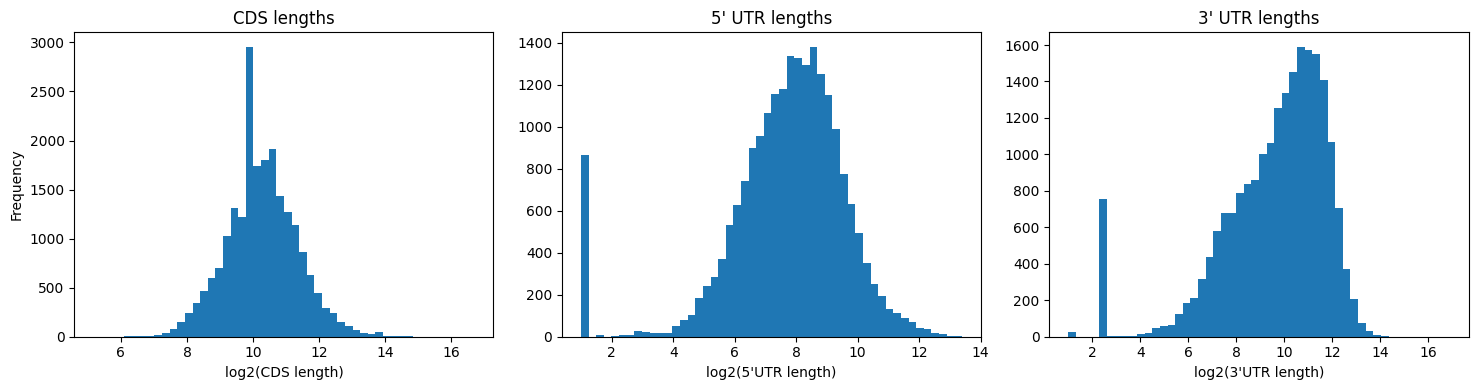

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(np.log2(np.array(cds_lengths)),      bins=50); ax[0].set(title="CDS lengths",    xlabel="log2(CDS length)",    ylabel="Frequency")
ax[1].hist(np.log2(np.array(utr5_lengths) + 2), bins=50); ax[1].set(title="5' UTR lengths", xlabel="log2(5'UTR length)")
ax[2].hist(np.log2(np.array(utr3_lengths) + 2), bins=50); ax[2].set(title="3' UTR lengths", xlabel="log2(3'UTR length)")
plt.tight_layout();

## Mitochondrial genes

Mouse mtDNA encodes 13 protein-coding genes. Their mRNAs have incomplete stop codons
(completed by polyadenylation), which the standard proper-codon filter rejects. v2 makes
an exception for `chrM` transcripts whose CDS runs to the transcript end, so all 13 are
kept.

In [9]:
v2_mt = sorted({c["name"] for txs in selected_transcripts.values()
                          for c in txs.values() if c["name"].startswith("mt-")})

v1_mt = set()
for entry in FastaFile(v1_selected_fasta):
    name = entry.header.split("|")[5]
    if name.startswith("mt-"):
        v1_mt.add(name)

print("v2 mt- genes ({}):".format(len(v2_mt)), v2_mt)
print("v1 mt- genes ({}):".format(len(v1_mt)), sorted(v1_mt))
print("recovered in v2 (not in v1):", sorted(set(v2_mt) - v1_mt))

v2 mt- genes (13): ['mt-Atp6', 'mt-Atp8', 'mt-Co1', 'mt-Co2', 'mt-Co3', 'mt-Cytb', 'mt-Nd1', 'mt-Nd2', 'mt-Nd3', 'mt-Nd4', 'mt-Nd4l', 'mt-Nd5', 'mt-Nd6']
v1 mt- genes (10): ['mt-Atp6', 'mt-Atp8', 'mt-Co1', 'mt-Co2', 'mt-Nd1', 'mt-Nd2', 'mt-Nd3', 'mt-Nd4l', 'mt-Nd5', 'mt-Nd6']
recovered in v2 (not in v1): ['mt-Co3', 'mt-Cytb', 'mt-Nd4']


## Comparison with the Previous RiboFlow Reference (v1)

**Convention:** *v1* is the previous mouse reference (GENCODE vM23); *v2* is this one
(GENCODE vM39). We compare the gene sets of the two references.

shared: 21151 | gained in v2: 261 | lost from v1: 518


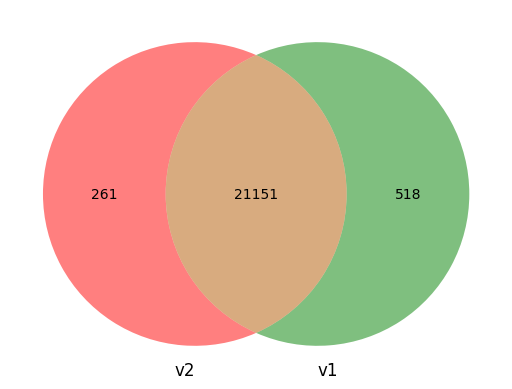

In [10]:
previous_gene_set = set()
prev_symbol = {}
for entry in FastaFile(v1_selected_fasta):
    f = entry.header.split("|")
    gid = f[1].split(".")[0]
    previous_gene_set.add(gid)
    prev_symbol[gid] = f[5]

current_gene_set = set(selected_transcripts.keys())
cur_symbol = {g: next(iter(txs.values()))["name"] for g, txs in selected_transcripts.items()}

current_minus_prev = current_gene_set - previous_gene_set   # gained in v2
prev_minus_current = previous_gene_set - current_gene_set   # lost from v1

venn2_unweighted([current_gene_set, previous_gene_set], set_labels=('v2', 'v1'), alpha=0.5);
print("shared:", len(current_gene_set & previous_gene_set),
      "| gained in v2:", len(current_minus_prev),
      "| lost from v1:", len(prev_minus_current))

### Why are genes lost relative to v1?

Most genes dropped from v1 are explained by v2's new filters and by annotation changes
between GENCODE vM23 and vM39. We categorize the lost genes by: tagged as a read-through
gene in vM39, and no longer an APPRIS principal gene in the current list. The remainder
are mostly annotation/biotype changes or transcripts that fail the stricter codon /
containment filters.

In [11]:
# Read-through genes in the current (vM39) annotation (reuses the pipeline's own reader)
readthrough_ids = gen.read_readthrough_gene_ids(gencode_gtf)

# Genes that are APPRIS principal in the current list
appris_principal_genes = set()
with open(appris_file) as fh:
    for line in fh:
        c = line.split()
        if len(c) >= 5 and c[4].startswith("PRINCIPAL"):
            appris_principal_genes.add(c[1].split(".")[0])

lost = prev_minus_current
lost_readthrough   = lost & readthrough_ids
lost_not_principal = (lost - readthrough_ids) - appris_principal_genes
lost_other         = lost - lost_readthrough - lost_not_principal

print("lost from v1 total:           ", len(lost))
print("  tagged read-through in vM39:", len(lost_readthrough))
print("  no longer APPRIS principal: ", len(lost_not_principal))
print("  other (biotype/codon/etc.): ", len(lost_other))
print()
print("example read-through losses:", [prev_symbol[g] for g in list(lost_readthrough)[:10]])
print("example other losses:      ", [prev_symbol[g] for g in list(lost_other)[:10]])

lost from v1 total:            518
  tagged read-through in vM39: 195
  no longer APPRIS principal:  281
  other (biotype/codon/etc.):  42

example read-through losses: ['Gm21985', 'Gm49368', 'Gm49391', 'Gm44579', 'Ugt1a10', 'Gm28044', 'Adora3', 'Gm42878', 'Ndor1', 'Gm49630']
example other losses:       ['Gm2174', 'Adat3', 'Jakmip1', 'E130116L18Rik', 'AL731706.2', 'Fam220a', 'Asdurf', 'Ik', 'Muc3a', 'Ptp4a1']


### Genes gained in v2

Genes present in v2 but not v1 - new/updated APPRIS principals in vM39, plus the three
mitochondrial genes recovered by the incomplete-stop exception.

In [12]:
gained_symbols = sorted(cur_symbol[g] for g in current_minus_prev)
print("gained in v2:", len(gained_symbols))
print("mt- genes among gains:", [s for s in gained_symbols if s.startswith("mt-")])
print(gained_symbols[:50])

gained in v2: 261
mt- genes among gains: ['mt-Co3', 'mt-Cytb', 'mt-Nd4']
['1600025M17Rik', '1700001J11Rik', '1700003E24Rik', '1700047F07Rik', '1700049L16Rik', '1700120K04Rik', '2310069G16Rik', '4930453H23Rik', '4930527J03Rik', '4930571K23Rik', '4933416I08Rik', 'A330040F15Rik', 'A930007A09Rik', 'AA414768', 'AB010352', 'Afg2b', 'Ahnak2', 'Ahsp', 'Akap17a', 'Alyreffm12', 'Alyreffm2', 'Ankrd65', 'Anxa13', 'Art2a', 'Arvcf', 'Atp10d', 'BC061195', 'C4a', 'Carlr', 'Cdk3', 'Cldn25', 'Cldn34c3', 'Clec7a', 'Cnbd1', 'D17H6S56E-5', 'Dhrsx', 'Dusp13a', 'ENSMUSG00000121742', 'ENSMUSG00000134847', 'ENSMUSG00000144242', 'ENSMUSG00000144245', 'ENSMUSG00000144253', 'ENSMUSG00000144274', 'ENSMUSG00000144290', 'ENSMUSG00000144334', 'ENSMUSG00000144335', 'ENSMUSG00000144336', 'ENSMUSG00000144337', 'ENSMUSG00000144338', 'ENSMUSG00000144339']


## Summary

In [13]:
summary = f"""
After building, the mouse v2 reference contains **{len(selected_transcripts)} transcripts**
(one protein-coding transcript per gene).

* {cds_remainder_by_3[0]} transcripts have a CDS length divisible by 3; {cds_remainder_by_3[1] + cds_remainder_by_3[2]} do not (mostly mitochondrial incomplete stops).
* {start_triplets['ATG']} transcripts start with ATG.
* Median CDS length is {median_cds_length} nt (mean {mean_cds_length} nt).
* {missing_utr5} transcripts have no 5' UTR and {missing_utr3} have no 3' UTR.
* All **{len(v2_mt)}** mitochondrial protein-coding genes are included (v1 had {len(v1_mt)}); recovered: {sorted(set(v2_mt) - v1_mt)}.

Versus v1: **{len(current_gene_set & previous_gene_set)}** shared genes, **{len(current_minus_prev)}** gained, **{len(prev_minus_current)}** lost ({len(lost_readthrough)} of the losses are read-through genes removed on purpose).
"""
display(Markdown(summary))


After building, the mouse v2 reference contains **21412 transcripts**
(one protein-coding transcript per gene).

* 21381 transcripts have a CDS length divisible by 3; 31 do not (mostly mitochondrial incomplete stops).
* 21378 transcripts start with ATG.
* Median CDS length is 1185 nt (mean 1648 nt).
* 867 transcripts have no 5' UTR and 27 have no 3' UTR.
* All **13** mitochondrial protein-coding genes are included (v1 had 10); recovered: ['mt-Co3', 'mt-Cytb', 'mt-Nd4'].

Versus v1: **21151** shared genes, **261** gained, **518** lost (195 of the losses are read-through genes removed on purpose).


## Files and Hash Sums

APPRIS list and GENCODE vM39 (primary-assembly, comprehensive) downloaded from
[gencodegenes.org/mouse](https://www.gencodegenes.org/mouse/) and
[appris-tools.org](http://appris-tools.org/#/downloads).

In [14]:
def md5_of(path):
    h = hashlib.md5()
    opener = gzip.open if path.endswith(".gz") else open
    with opener(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

for p in (transcripts_fasta, gencode_gtf, appris_file):
    print(f"{md5_of(p)}  {os.path.basename(p)}")

53dc7033c846c9ff4c01d904ec3f05ee  gencode.vM39.pc_transcripts.fa.gz


dac667e9afbe6666d3805c5484bbb4ab  gencode.vM39.primary_assembly.annotation.gtf.gz
3bd1fda4711dd6a1bea9c6c6b63edea4  appris_data.principal.txt


## Generating the RiboFlow Reference and Annotation

If the reference and annotation have not been generated yet, run
`generate_riboflow_ref_and_annot.sh` in this `scripts/` folder. It runs
`generate_appris_reference.py` and builds the Bowtie2 index.